# 04 · Decision policy and interpretability

Everything here uses the current production champion (`artifacts/champion`, written by `churn simulate`) evaluated on the frozen holdout,
so it describes the model that is actually deployed.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from churn import config

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

import shap
from sklearn.metrics import confusion_matrix, roc_auc_score

from churn.data.ingest import X_y, load_split
from churn.decision.policy import customer_value, decide, expected_value, net_value
from churn.models.bundle import load_bundle
from churn.models.evaluate import segment_report
from churn.models.interpret import base_pipeline

bundle = load_bundle(config.CHAMPION_DIR)
model, policy, meta = bundle["model"], bundle["policy"], bundle["metadata"]
holdout = load_split("holdout")
X, y = X_y(holdout)
proba = model.predict_proba(X)[:, 1]
value = customer_value(X)
contact = decide(proba, value, policy)
print(f"champion v{meta['version']} ({meta['model']}), rule: {policy['rule']}")

champion v4 (gradient_boosting), rule: expected_value


## 1. Value of the campaign by decision rule

expected value rule      62363.0
best threshold (0.18)    59805.0
threshold 0.5            45308.0
dtype: float64

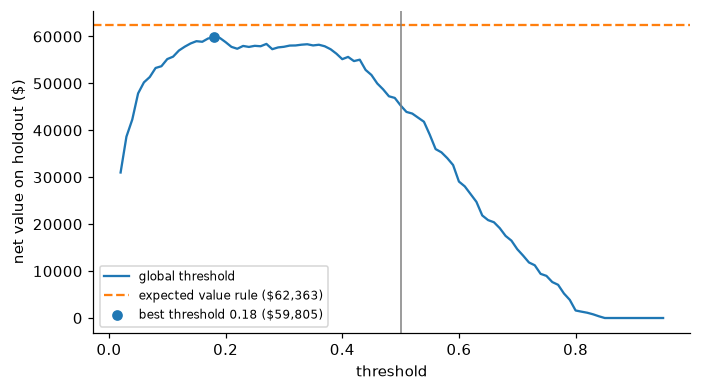

In [2]:
grid = np.round(np.arange(0.02, 0.96, 0.01), 2)
by_threshold = [net_value(y, proba >= t, value) for t in grid]
ev_value = net_value(y, contact, value)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid, by_threshold, label="global threshold")
ax.axhline(ev_value, color="C1", ls="--", label=f"expected value rule (${ev_value:,.0f})")
ax.axvline(0.5, color="grey", lw=1)
best = int(np.argmax(by_threshold))
ax.scatter(grid[best], by_threshold[best], color="C0", zorder=3, label=f"best threshold {grid[best]} (${by_threshold[best]:,.0f})")
ax.set_xlabel("threshold")
ax.set_ylabel("net value on holdout ($)")
ax.legend(fontsize=8)
pd.Series({"expected value rule": ev_value, f"best threshold ({grid[best]})": by_threshold[best], "threshold 0.5": net_value(y, proba >= 0.5, value)}).round(0)

On the holdout, the champion's **expected-value rule earns $62.4k**, against $59.8k for the best possible global threshold (0.18) and $45.3k at the default 0.5.
Using 0.5 would leave 27% of the value on the table. The expected-value rule beats even the best threshold because it uses information a single
cut-off can't: two customers with the same probability are worth contacting or not depending on their bill.

## 2. Where the money comes from

In [3]:
tn, fp, fn, tp = confusion_matrix(y, contact).ravel()
saved = config.OFFER_SUCCESS_RATE * value[(y == 1) & contact]
breakdown = pd.Series({
    "contacted churners (TP)": tp,
    "contacted non-churners (FP)": fp,
    "missed churners (FN)": fn,
    "left alone, stayed (TN)": tn,
    "expected revenue saved from TP ($)": saved.sum(),
    "offer cost on all contacts ($)": config.RETENTION_OFFER_COST * contact.sum(),
    "net value ($)": net_value(y, contact, value),
    "revenue of missed churners ($)": value[(y == 1) & ~contact].sum(),
})
breakdown.round(0)

contacted churners (TP)                 287.0
contacted non-churners (FP)             336.0
missed churners (FN)                     87.0
left alone, stayed (TN)                 699.0
expected revenue saved from TP ($)    99743.0
offer cost on all contacts ($)        37380.0
net value ($)                         62363.0
revenue of missed churners ($)        44659.0
dtype: float64

Of 1,409 holdout customers, 623 (44%) get the offer. 287 of them are real churners and 336 would have stayed anyway, so a bit more than half the offers go to customers
who didn't need them. That's the price of catching 77% of churners, and the economics still work: $99.7k of expected saved revenue against $37.4k in offers.

The 87 missed churners represent $44.7k of revenue. Notebook section 9 shows that many of them were missed on purpose.

## 3. Sensitivity to the business assumptions

Offer cost ($60) and acceptance rate (35%) are assumptions. If they're wrong, how wrong is the campaign?
Each cell re-applies the expected-value rule under different assumptions.

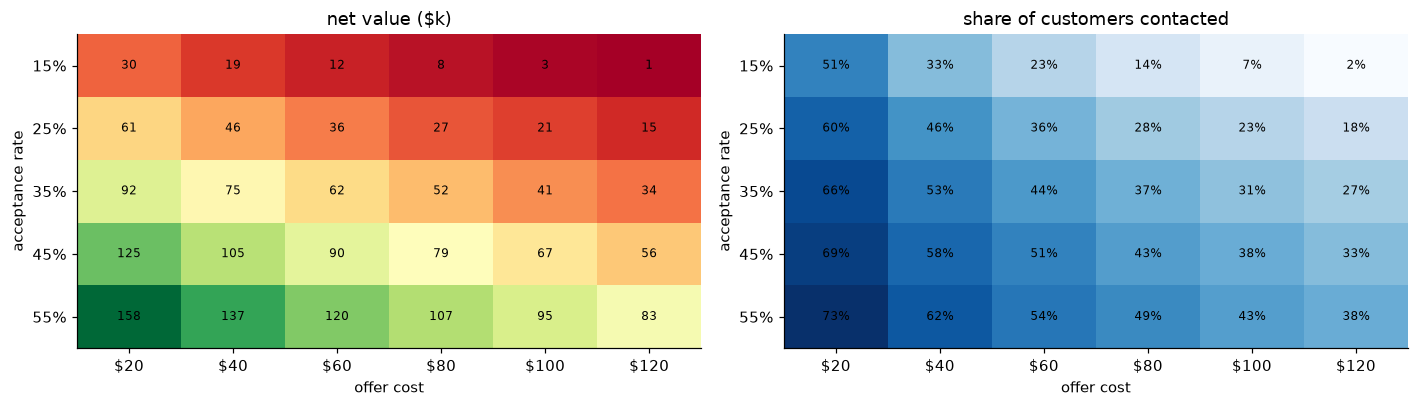

In [4]:
costs = [20, 40, 60, 80, 100, 120]
rates = [0.15, 0.25, 0.35, 0.45, 0.55]
value_grid = pd.DataFrame(index=rates, columns=costs, dtype=float)
contact_grid = value_grid.copy()
for rate in rates:
    for cost in costs:
        chosen = proba * rate * value > cost
        gain = np.where(y == 1, rate * value - cost, -cost)
        value_grid.loc[rate, cost] = gain[chosen].sum()
        contact_grid.loc[rate, cost] = chosen.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, grid_, title, fmt in [(axes[0], value_grid, "net value ($k)", lambda v: f"{v / 1000:.0f}"), (axes[1], contact_grid, "share of customers contacted", lambda v: f"{v:.0%}")]:
    ax.imshow(grid_.astype(float), cmap="RdYlGn" if "value" in title else "Blues", aspect="auto")
    ax.set_xticks(range(len(costs)), [f"${c}" for c in costs])
    ax.set_yticks(range(len(rates)), [f"{r:.0%}" for r in rates])
    ax.set_xlabel("offer cost")
    ax.set_ylabel("acceptance rate")
    ax.set_title(title)
    for i in range(len(rates)):
        for j in range(len(costs)):
            ax.text(j, i, fmt(grid_.iloc[i, j]), ha="center", va="center", fontsize=8)
fig.tight_layout()

The rule protects itself. Under every combination in the grid **net value stays positive**, because when offers get expensive or acceptance drops,
the rule simply contacts fewer people. At a 15% acceptance rate and a $120 offer it contacts 2% of customers and still makes $0.8k. A fixed threshold would keep contacting
44% and lose money.

The assumptions still matter a lot for the size of the prize: from $12k (15% acceptance, $60 offer) to $120k (55%, $60). Estimating the acceptance rate with a
proper control group would be the highest-value next step on the business side.

## 4. The contact list

In [5]:
ranked = holdout.assign(churn_probability=proba, customer_value=value, expected_value=expected_value(proba, value), contact=contact)
ranked = ranked.sort_values("expected_value", ascending=False)
ranked[[config.ID_COL, "contract", "tenure", "monthly_charges", "churn_probability", "customer_value", "expected_value", "contact"]].head(10)

,customer_id,contract,tenure,monthly_charges,churn_probability,customer_value,expected_value,contact
911,5419-JPRRN,Month-to-month,1,101.45,0.844,1217.4,299.475,True
432,4132-KALRO,Month-to-month,4,100.85,0.790,1210.2,274.800,True
102,6210-KBBPI,Month-to-month,9,99.45,0.792,1193.4,270.798,True
702,9300-AGZNL,Month-to-month,1,94.00,0.829,1128.0,267.261,True
827,7450-NWRTR,Month-to-month,12,99.45,0.781,1193.4,266.141,True
433,6496-SLWHQ,Month-to-month,3,105.00,0.737,1260.0,265.230,True
973,0781-LKXBR,Month-to-month,9,100.50,0.770,1206.0,265.127,True
819,0722-SVSFK,Month-to-month,7,100.40,0.760,1204.8,260.356,True
1146,9734-YWGEX,Month-to-month,9,98.30,0.768,1179.6,257.148,True
1016,2081-VEYEH,Month-to-month,3,107.95,0.680,1295.4,248.094,True


In [6]:
# High probability doesn't guarantee a contact: a cheap plan can't pay for the offer
cheap_risky = ranked[(ranked["churn_probability"] > 0.5) & ~ranked["contact"]]
print(f"{len(cheap_risky)} customers with p > 0.5 are NOT contacted")
cheap_risky[["contract", "monthly_charges", "churn_probability", "expected_value"]].describe().loc[["count", "mean", "min", "max"]]

1 customers with p > 0.5 are NOT contacted


,monthly_charges,churn_probability,expected_value
count,1.00,1.000,1.000
mean,24.25,0.525,-6.552
min,24.25,0.525,-6.552
max,24.25,0.525,-6.552


The list is ordered by expected value, not probability, so the top of the list is high-risk customers on expensive plans: month-to-month, a few months in, ~$100/month.

The reverse also happens. A customer on a $24/month plan with a 53% churn probability is not contacted, because the most we could save
(35% x 12 x $24 ≈ $102 x 0.53) doesn't cover a $60 offer. For a $20/month customer the break-even probability is 0.71. For a $100/month customer it's 0.14.

## 5. Global drivers (SHAP)

SHAP values on the base model (log-odds). Platt scaling is monotonic, so the ranking of drivers holds for the calibrated probability.

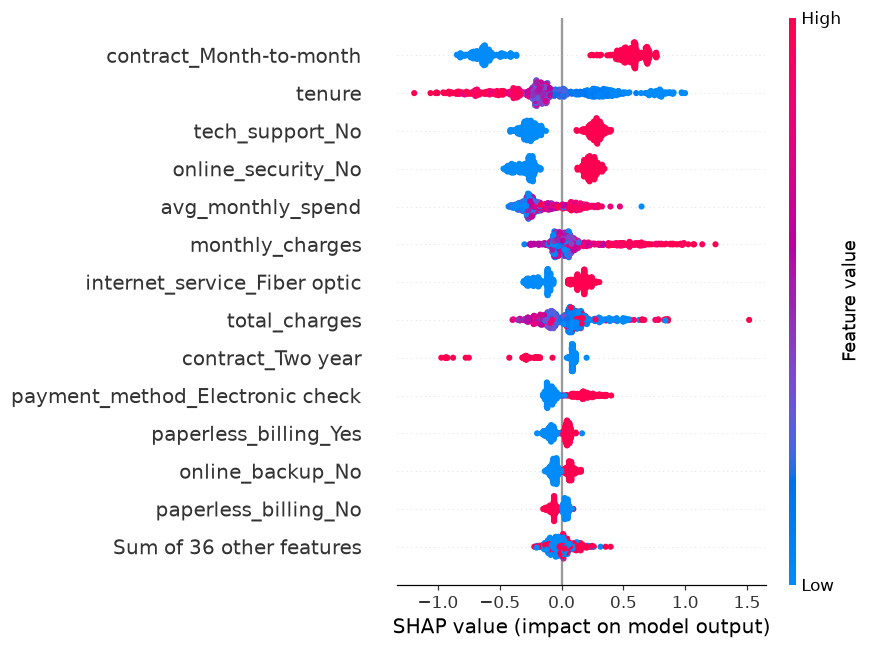

In [7]:
pipe = base_pipeline(model)
features, clf = pipe.named_steps["features"], pipe.named_steps["clf"]
sample = X.sample(600, random_state=config.RANDOM_STATE)
Xt = features.transform(sample)
names = list(features.named_steps["prep"].get_feature_names_out())
explainer = shap.TreeExplainer(clf, feature_perturbation="tree_path_dependent") if hasattr(clf, "estimators_") else shap.LinearExplainer(clf, Xt[:100])
explanation = explainer(Xt)
explanation.feature_names = [n.split("__", 1)[1] for n in names]
if explanation.values.ndim == 3:
    explanation = explanation[:, :, 1]
shap.plots.beeswarm(explanation, max_display=14, show=False)
plt.gcf().set_size_inches(8, 6)
plt.tight_layout()

## 6. How the main drivers act

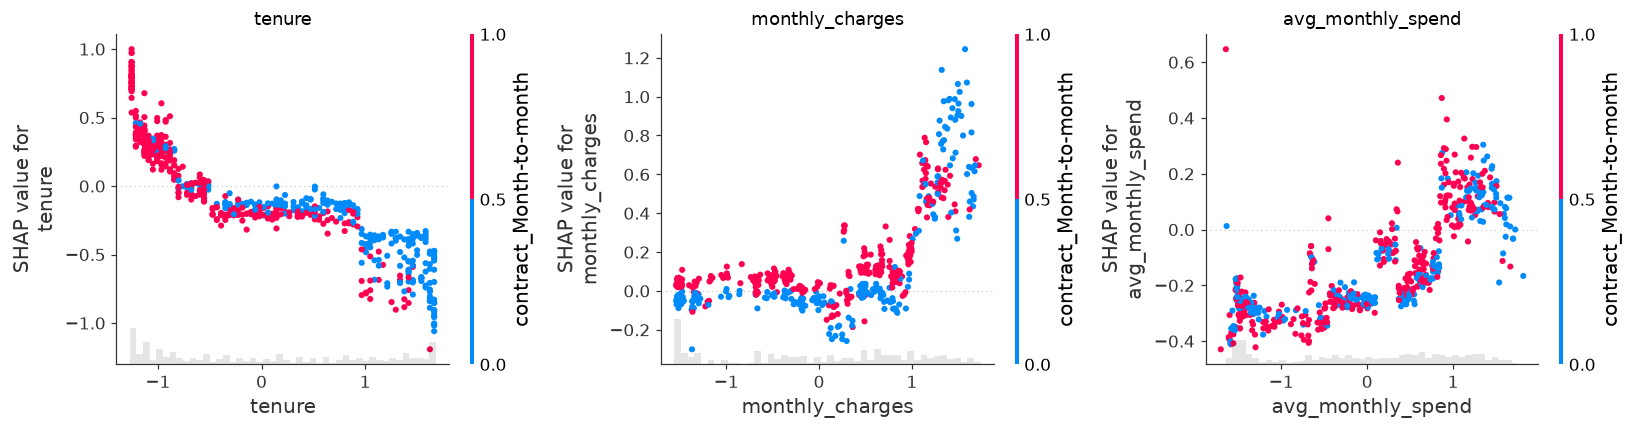

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["tenure", "monthly_charges", "avg_monthly_spend"]):
    shap.plots.scatter(explanation[:, feature], color=explanation[:, "contract_Month-to-month"], ax=ax, show=False)
    ax.set_title(feature)
fig.tight_layout()

- **Tenure:** the contribution falls monotonically across the whole range. Average SHAP goes from +0.51 log-odds in the first six months to -0.17 at 2-4 years and -0.52 after four years.
  Its size is about the same for month-to-month customers and the rest (mean |SHAP| 0.35 in both groups).
- **Monthly charges:** almost flat below $90 (average SHAP between -0.01 and +0.05), then a jump to +0.46 for bills above $90. It acts like a threshold, not a slope.
- **avg_monthly_spend:** its average impact (mean |SHAP| 0.21) is larger than that of `monthly_charges` (0.17). The tree model uses it for the price-change signal from notebook 02,
  even though it barely helped the linear model. That's why I keep the feature.

## 7. Two individual explanations

highest risk: p = 0.802 | Month-to-month, tenure 2, $87.15/month, internet Fiber optic


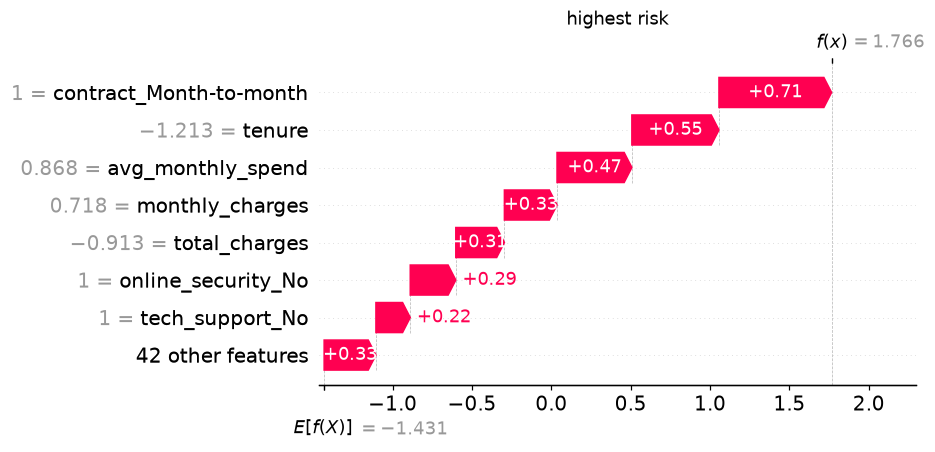

lowest risk: p = 0.019 | Two year, tenure 70, $79.7/month, internet DSL


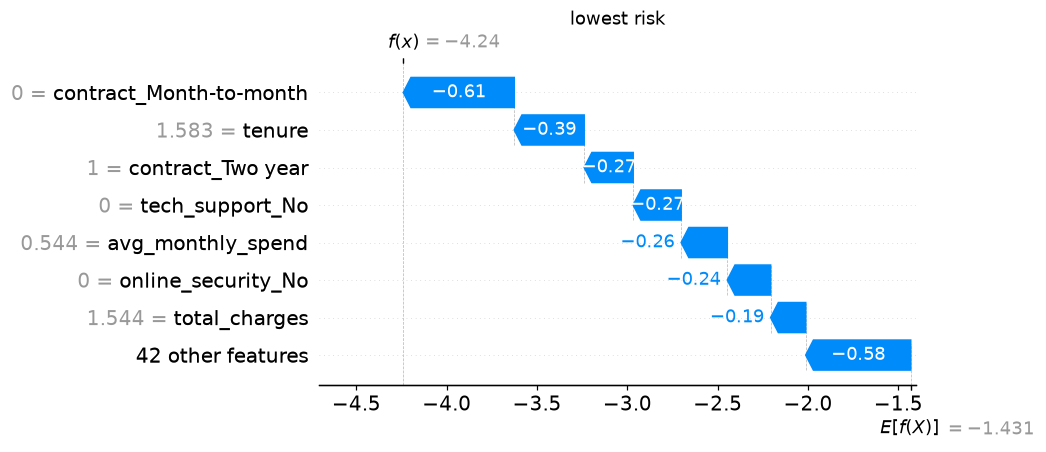

In [9]:
sample_proba = model.predict_proba(sample)[:, 1]
high, low = int(np.argmax(sample_proba)), int(np.argmin(sample_proba))
for idx, label in [(high, "highest risk"), (low, "lowest risk")]:
    row = sample.iloc[idx]
    print(f"{label}: p = {sample_proba[idx]:.3f} | {row['contract']}, tenure {row['tenure']}, ${row['monthly_charges']}/month, internet {row['internet_service']}")
    shap.plots.waterfall(explanation[idx], max_display=8, show=False)
    plt.gcf().set_size_inches(7, 3.8)
    plt.title(label)
    plt.show()

## 8. Performance by driver

In [10]:
segments = segment_report(X, y, proba, contact)
overall = 2 * roc_auc_score(y, proba) - 1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = segments["segment"] + ": " + segments["value"].astype(str)
axes[0].barh(labels, segments["gini"], color="#3b6ea5")
axes[0].axvline(overall, color="C3", ls="--", label=f"overall {overall:.3f}")
axes[0].set_title("Gini by segment (holdout)")
axes[0].legend()
axes[1].scatter(segments["churn_rate"], segments["mean_predicted"], s=segments["n"] / 3, alpha=0.6)
for _, r in segments.iterrows():
    axes[1].annotate(f"{r['value']}", (r["churn_rate"], r["mean_predicted"]), fontsize=7)
axes[1].plot([0, 0.7], [0, 0.7], color="grey", ls="--")
axes[1].set_xlabel("observed churn rate")
axes[1].set_ylabel("mean predicted")
axes[1].set_title("calibration by segment (bubble = size)")
fig.tight_layout()
segments

,segment,value,n,churn_rate,mean_predicted,gini,recall,contact_rate
0,contract,Month-to-month,803,0.412,0.395,0.529,0.813,0.669
1,contract,One year,293,0.106,0.112,0.352,0.452,0.222
2,contract,Two year,313,0.038,0.050,0.403,0.333,0.067
3,internet_service,DSL,508,0.191,0.186,0.562,0.443,0.222
4,internet_service,Fiber optic,610,0.410,0.397,0.611,0.976,0.836
5,internet_service,No,291,0.093,0.097,0.659,0.000,0.000
6,tenure_band,0-6m,311,0.524,0.465,0.527,0.779,0.633
7,tenure_band,13-24m,186,0.269,0.258,0.667,0.840,0.468
8,tenure_band,25-48m,305,0.197,0.204,0.505,0.700,0.413
9,tenure_band,49m+,441,0.100,0.114,0.524,0.636,0.277


The model is uneven across segments:

- **Weak inside long contracts.** Gini is 0.35 for one-year and 0.40 for two-year contracts, against 0.67 overall. Once you know the contract, little is left to rank on,
  and those customers rarely churn (11% and 4%), so it matters less in money terms.
- **Under-predicts new customers.** In the 0-6 month segment it predicts 46.5% and the actual rate is 52.4%. Electronic-check payers are also under-predicted (41% vs 46%).
  Global Platt scaling fixes the average, not every segment.
- **Never contacts customers without internet.** Recall there is 0, by design: their bills are too low for the offer to pay off.

## 9. Error analysis: which churners does the model miss?

In [11]:
churners = holdout[y == 1].assign(caught=contact[y == 1], p=proba[y == 1])
profile = churners.groupby("caught").agg(
    customers=("caught", "size"),
    mean_p=("p", "mean"),
    tenure=("tenure", "median"),
    monthly_charges=("monthly_charges", "median"),
    month_to_month=("contract", lambda s: (s == "Month-to-month").mean()),
    fiber=("internet_service", lambda s: (s == "Fiber optic").mean()),
    no_internet=("internet_service", lambda s: (s == "No").mean()),
)
profile.rename(index={True: "caught", False: "missed"})

,customers,mean_p,tenure,monthly_charges,month_to_month,fiber,no_internet
caught,,,,,,,
missed,87,0.204,12.0,39.50,0.713,0.069,0.31
caught,287,0.538,8.0,85.35,0.937,0.850,0.00


The missed churners aren't mostly "model errors". Their median bill is $39.50 against $85.35 for the caught ones, and **31% of them have no internet service**.
44 of the 87 pay under $40/month, where the offer can't pay for itself even at high churn probability. Many misses are economic decisions, not ranking failures.

The real ranking failures are the other 43, who pay $40 or more but were scored low (mean p = 0.15). They're long-standing customers (median tenure 38 months),
only about half on month-to-month. The model reads that profile as safe, and nothing in Telco's columns says otherwise. That's where better features
(support tickets, usage trends, recent plan changes) would add the most.

## Summary

- The expected-value rule earns $62.4k on the holdout, against $59.8k for the best threshold and $45.3k at 0.5. It also stays profitable under every cost assumption tested.
- Contract, tenure and the protection services drive the score. The model is weakest inside long contracts and under-predicts brand-new customers.
- About half the "missed" churners are deliberately left alone because they're not worth the offer.
- Next steps: segment-level calibration (or a tenure interaction), and an experiment to measure the real offer acceptance rate.